# Exploración de datos — prototipo académico

**Fuentes 100 % simuladas, no datos de la Red Metropolitana.** Este notebook permite reproducir el perfilado de las dos tablas del ejemplo. Las cifras no describen la operación real de Santiago.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / 'datos').exists():
    root = root.parent
gps = pd.read_csv(root / 'datos/gps_viajes_SIMULADOS.csv')
bip = pd.read_csv(root / 'datos/bip_aggregado_SIMULADO.csv')
print('Registros sintéticos GPS:', len(gps))
print('Registros sintéticos bip!: ', len(bip))
assert gps.tipo_dato.eq('SIMULADO_NO_REAL').all()
assert bip.tipo_dato.eq('SIMULADO_NO_REAL').all()

Registros sintéticos GPS: 5792
Registros sintéticos bip!:  5792


## 1. Estructura y calidad de los datos

In [2]:
display(gps.head())
display(pd.DataFrame({'tipo': gps.dtypes.astype(str), 'nulos': gps.isna().sum(), 'porcentaje_nulos': gps.isna().mean().mul(100).round(2)}))
print('Duplicados GPS:',gps.duplicated(['fecha','recorrido','franja']).sum())
print('Duplicados bip!:',bip.duplicated(['fecha','recorrido','franja']).sum())

,fecha,recorrido,comuna,zona,franja,hora_inicio,minutos_programados,minutos_observados_gps,congestion_pronosticada,lluvia_pronosticada,cobertura_gps,tipo_dato
0,2026-01-01,101,Santiago,Centro,AM,07:00,23,27.08,1.716,0,0.930,SIMULADO_NO_REAL
1,2026-01-01,101,Santiago,Centro,Valle,12:00,23,25.36,0.625,0,1.000,SIMULADO_NO_REAL
2,2026-01-01,101,Santiago,Centro,PM,18:00,23,28.37,1.383,0,0.980,SIMULADO_NO_REAL
3,2026-01-01,101,Santiago,Centro,Noche,22:00,23,24.44,0.371,0,0.930,SIMULADO_NO_REAL
4,2026-01-01,102,Providencia,Centro,AM,07:00,26,39.09,1.432,1,0.974,SIMULADO_NO_REAL


,tipo,nulos,porcentaje_nulos
fecha,object,0,0.0
recorrido,int64,0,0.0
comuna,object,0,0.0
zona,object,0,0.0
franja,object,0,0.0
hora_inicio,object,0,0.0
minutos_programados,int64,0,0.0
minutos_observados_gps,float64,0,0.0
congestion_pronosticada,float64,0,0.0
lluvia_pronosticada,int64,0,0.0


Duplicados GPS: 0
Duplicados bip!: 0


## 2. Perfilamiento por zona y franja

registros  promedio_observado_min  cobertura_promedio
zona      franja                                                       
Centro    AM            724                   33.30                0.96
          Noche         724                   28.44                0.96
          PM            724                   32.95                0.96
          Valle         724                   29.71                0.96
Periferia AM            724                   46.98                0.93
          Noche         724                   42.06                0.93
          PM            724                   46.53                0.93
          Valle         724                   43.29                0.93

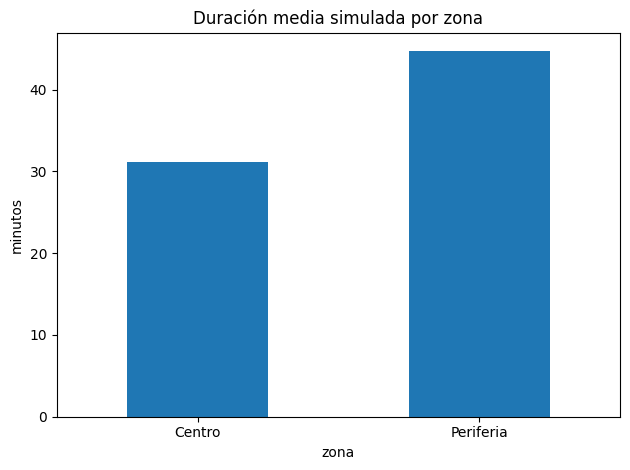

In [3]:
resumen = gps.groupby(['zona','franja']).agg(registros=('recorrido','size'),promedio_observado_min=('minutos_observados_gps','mean'),cobertura_promedio=('cobertura_gps','mean')).round(2)
display(resumen)
ax = gps.groupby('zona')['minutos_observados_gps'].mean().plot(kind='bar',title='Duración media simulada por zona',ylabel='minutos',rot=0)
plt.tight_layout(); plt.show()

## 3. Resultados del prototipo

In [4]:
import json
metricas=json.loads((root/'resultado/metricas_SIMULADAS.json').read_text(encoding='utf-8'))
print('MAE línea base:',metricas['mae_baseline_min'])
print('MAE modelo:',metricas['mae_modelo_min'])
print('Brecha por zona (%):',metricas['brecha_mae_centro_periferia_pct'])
print('Importante: todos estos resultados usan datos sintéticos.')

MAE línea base: 4.49
MAE modelo: 1.722
Brecha por zona (%): 18.88
Importante: todos estos resultados usan datos sintéticos.


## 4. Limitaciones y próximos pasos

Este notebook **no valida** anonimización, precisión ni equidad con datos personales u operacionales reales. Antes de cualquier uso se requiere convenio/acceso autorizado, definición de retraso y del momento de predicción, controles de calidad y revisión con el cliente.